# Tercera entrega - Proyecto de IA
## Modelo final y artefacto de despliegue: riesgo de mortalidad en UCI por sepsis

- Sofia Gomez Rodriguez 
- Emmanuel Escobar Santos 
- Victor Andres Martinez Preciado

## 1. Configuración y carga de datos

In [1]:
import json, os, platform, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 42  # misma semilla de la entrega 2, reproduce la misma partición
np.random.seed(SEMILLA)
print("scikit-learn", sklearn.__version__, ", numpy", np.__version__, ", pandas", pd.__version__)

scikit-learn 1.9.1 , numpy 2.5.3 , pandas 3.0.5


In [3]:
# Rutas para garantizar funcionamiento del codigo 
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_CSV = Path(os.environ.get("SEPSIS_CSV", RAIZ / "data" / "CriticalData_Sepsis.csv"))
DIR_MODELOS = RAIZ / "models"
DIR_FIGURAS = RAIZ / "reports" / "figuras"
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

if not RUTA_CSV.exists(): # en Colab: se pide el archivo si no está en disco
    from google.colab import files
    subido = files.upload()
    RUTA_CSV = Path(next(iter(subido)))

df = pd.read_csv(RUTA_CSV)
df.columns = df.columns.str.strip()
print(df.shape)

(10000, 68)


In [4]:
# Estilo único para todas las figuras
AZUL, NARANJA, GRIS, TINTA, TINTA2, REJILLA = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#ffffff", "axes.facecolor": "#ffffff", "savefig.facecolor": "#ffffff",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "text.color": TINTA, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200,
    "legend.frameon": False, "axes.axisbelow": True})

def c(x, d=3):
    """Número con coma decimal para rótulos de figuras."""
    return f"{x:.{d}f}".replace(".", ",")

# Nombres clínicos para los rótulos de las figuras.
ES = {"SepticShock": "Choque séptico", "VasopressorUse_0h": "Vasopresor al ingreso", "MAP_0": "PA media", "SOFA_0h": "SOFA",
      "DBP_0": "PA diastólica", "SBP_0": "PA sistólica", "Lactate_0h": "Lactato", "INR_0h": "INR", "Age": "Edad",
      "FrailtyScore": "Fragilidad", "InfectionSource_desconocido": "Foco desconocido", "InfectionSource_piel": "Foco piel",
      "InfectionSource_pulmonar": "Foco pulmonar", "InfectionSource_urinaria": "Foco urinario"}

def guardar(nombre):
    """Guarda la figura actual en reports/figuras y la muestra."""
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight")
    plt.show()

## 2. Variables y partición

Se conserva la decisión de negocio de la entrega 2: ventana 0 h. El modelo solo usa lo que el
intensivista ya conoce al ingreso a UCI, porque el valor clínico está en anticipar (la sepsis es
tiempo-dependiente) y porque una variable de 24 h no existe en el momento en que se consulta la herramienta.
Esta decisión se tomó y se justificó en la entrega 2; aquí no se vuelve a evaluar.

In [5]:
OBJETIVO = "MortalityInICU"
COLS_CAT = ["InfectionSource"]
COLS_BIN = ["SepticShock", "VasopressorUse_0h"]
COLS_CONT = ["MAP_0", "SOFA_0h", "DBP_0", "SBP_0", "Lactate_0h", "INR_0h", "Age", "FrailtyScore"]
COLS_NUM = ["SepticShock", "VasopressorUse_0h", "MAP_0", "SOFA_0h", "DBP_0", "SBP_0",
            "Lactate_0h", "INR_0h", "Age", "FrailtyScore"]         
VARIABLES = COLS_CAT + COLS_NUM

datos = df.dropna(subset=[OBJETIVO]).reset_index(drop=True)# 670 filas sin desenlace: no se pueden usar
X = datos[VARIABLES].copy()                                          
y = datos[OBJETIVO].astype(int)

# Misma partición estratificada 75/25 y misma semilla: los pacientes de prueba son los de la entrega 2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f"Train {X_train.shape} | Test {X_test.shape} | mortalidad train {y_train.mean():.3f} / test {y_test.mean():.3f}")
print("\nFaltantes en train (%):")
print((X_train.isna().mean() * 100).round(1).to_string())

Train (6997, 11) | Test (2333, 11) | mortalidad train 0.465 / test 0.465

Faltantes en train (%):
InfectionSource      7.8
SepticShock          7.5
VasopressorUse_0h    6.6
MAP_0                7.1
SOFA_0h              6.8
DBP_0                6.5
SBP_0                7.2
Lactate_0h           7.5
INR_0h               7.0
Age                  7.2
FrailtyScore         7.1


## 3. Pipeline de preprocesamiento

**La imputación como paso exclusivo del entrenamiento:** el conjunto de datos presenta cerca de un 7 % de
valores faltantes por variable y eliminar los registros incompletos reduciría la muestra a menos de la mitad
de los pacientes. Por esta razón, la imputación se emplea únicamente para entrenar el modelo. En la aplicación
desplegada todos los campos son obligatorios: el módulo `src/modelo.py` aplica el escalado, la codificación y
la regresión ya ajustados, omite el imputador y rechaza cualquier registro incompleto. Cuando los datos están
completos, el imputador no modifica ningún valor; por tanto, ambos procedimientos producen exactamente el mismo
resultado, lo cual se verifica al final del cuaderno y en las pruebas automáticas. El modelo, las variables,
los hiperparámetros y la partición de los datos corresponden a los definidos en la entrega 2.

* **Variables numéricas:** primero se estandarizan con `StandardScaler` y luego se imputan con `KNNImputer`,
  utilizando 20 vecinos ponderados por distancia, valor seleccionado en la entrega 2. La estandarización se
  realiza antes de la imputación porque el método de vecinos más cercanos se basa en distancias y sin ella,
  las variables con valores más grandes dominarían el cálculo. En las variables binarias, el valor imputado
  queda como una fracción que representa la proporción de vecinos que presentan el evento, lo que refleja la
  incertidumbre sobre el dato ausente.
* **Variable categórica (`InfectionSource`):** se imputa con la categoría más frecuente (moda) y luego se
  transforma en variables indicadoras (codificación one-hot). En la entrega 2 se comprobó que la imputación por
  vecinos más cercanos no superaba al azar para esta variable (exactitud de 0,23 frente a 0,20), por lo que no
  se justifica un método más complejo.

In [6]:
def preprocesador_knn(k=20):
    numericas = Pipeline([("escalar", StandardScaler()),
                          ("imputar", KNNImputer(n_neighbors=k, weights="distance"))])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))])
    return ColumnTransformer([("num", numericas, COLS_NUM), ("cat", categoricas, COLS_CAT)],
                             verbose_feature_names_out=False)

def logistica_l1():
    """Regresión logística de la entrega 2: L1, C=0.1, clases balanceadas, solver liblinear.
    scikit-learn >= 1.8 reemplazó `penalty` por `l1_ratio`; se soportan ambas versiones."""
    comunes = dict(C=0.1, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=SEMILLA)
    version = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
    return LogisticRegression(l1_ratio=1, **comunes) if version >= (1, 8) else LogisticRegression(penalty="l1", **comunes)

## 4. Validación cruzada del modelo propuesto

La elección del algoritmo se hizo en la entrega 2 de regresión logística L1 y aquí se mantiene. Esta
sección solo mide su desempeño con validación cruzada estratificada repetida (5×3) sobre entrenamiento.
Sirve de referencia para comprobar más adelante que el resultado en prueba es parecido, es decir, que no hay sobreajuste.

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

propuesto = Pipeline([("pre", preprocesador_knn()), ("modelo", logistica_l1())])

auc_cv = cross_val_score(propuesto, X_train, y_train, cv=cv_rep, scoring="roc_auc", n_jobs=-1)
brier_cv = -cross_val_score(propuesto, X_train, y_train, cv=cv5, scoring="neg_brier_score", n_jobs=-1)
propuesto.fit(X_train, y_train)
auc_train = roc_auc_score(y_train, propuesto.predict_proba(X_train)[:, 1])
comparacion = pd.DataFrame([{"AUC CV": auc_cv.mean(), "± DE": auc_cv.std(), "AUC train": auc_train,
                             "sobreajuste (train − CV)": auc_train - auc_cv.mean(), "Brier CV": brier_cv.mean()}],
                           index=["Logística L1 + KNN"]).round(4)
comparacion

,AUC CV,± DE,AUC train,sobreajuste (train − CV),Brier CV
Logística L1 + KNN,0.5821,0.0134,0.5911,0.009,0.2434


El AUC en validación cruzada es modesto y la brecha entre entrenamiento y validación es pequeña: el modelo no memoriza los datos. Se mantiene la regresión logística L1 porque sus predicciones se pueden explicar a un médico coeficiente por coeficiente, además de no existir una amplia diferencia en las métricas de los demás modelos que justifique la elección de otro diferente a la logística.

## 5. Modelo final: ajuste, coeficientes y calibración

In [8]:
modelo = Pipeline([("pre", preprocesador_knn()), ("modelo", logistica_l1())])
modelo.fit(X_train, y_train)

pre, logit = modelo.named_steps["pre"], modelo.named_steps["modelo"]
NOMBRES = list(pre.get_feature_names_out())
escalador = pre.named_transformers_["num"].named_steps["escalar"]
desv = pd.Series(escalador.scale_, index=COLS_NUM)

coef = pd.DataFrame({"coef_por_DE": logit.coef_[0]}, index=NOMBRES)
coef["OR_por_DE"] = np.exp(coef["coef_por_DE"])
# Coeficiente en unidades originales: las numéricas se dividieron por su DE; las dummies no se escalaron.
coef["coef_por_unidad"] = coef["coef_por_DE"] / desv.reindex(coef.index).fillna(1.0)
coef["OR_por_unidad"] = np.exp(coef["coef_por_unidad"])
coef["DE_de_la_variable"] = desv.reindex(coef.index)
print(f"Intercepto: {logit.intercept_[0]:.4f} , variables con coeficiente ≠ 0: {(coef['coef_por_DE'] != 0).sum()} de {len(coef)}")
coef.sort_values("coef_por_DE", key=np.abs, ascending=False).round(4)

Intercepto: -0.0217 , variables con coeficiente ≠ 0: 10 de 14


,coef_por_DE,OR_por_DE,coef_por_unidad,OR_por_unidad,DE_de_la_variable
SepticShock,0.2904,1.3370,0.7104,2.0349,0.4088
InfectionSource_desconocido,0.1272,1.1357,0.1272,1.1357,NaN
VasopressorUse_0h,0.0650,1.0671,0.1343,1.1437,0.4839
Age,0.0550,1.0566,0.0034,1.0034,16.3443
INR_0h,0.0408,1.0416,0.0933,1.0978,0.4372
FrailtyScore,0.0354,1.0360,0.0234,1.0236,1.5144
InfectionSource_pulmonar,-0.0294,0.9711,-0.0294,0.9711,NaN
DBP_0,0.0248,1.0252,0.0016,1.0016,15.5845
Lactate_0h,0.0103,1.0104,0.0037,1.0037,2.8183
SOFA_0h,0.0019,1.0019,0.0014,1.0014,1.2963


Interpretación de la tabla: para cada paciente, el modelo multiplica el valor estandarizado de cada
variable por su coeficiente, suma estos productos junto con el intercepto y obtiene un puntaje denominado
log-odds. Este puntaje se transforma en una probabilidad entre 0 y 1 mediante la función sigmoide.

La columna OR_por_unidad contiene el odds ratio de cada variable, es decir, el factor por el que se
multiplican las posibilidades de fallecer cuando la variable aumenta en una unidad o, en el caso de las
variables binarias, cuando pasa de estar ausente a estar presente. Un valor mayor que 1 indica que la
variable aumenta el riesgo, y un valor menor que 1 indica que lo reduce. Por ejemplo, un odds ratio de 2,03
para el choque séptico significa que su presencia duplica las posibilidades de fallecer.

La regularización L1 lleva a cero los coeficientes de las variables cuya información ya está contenida en
otras. Por esta razón, la presión arterial media, la presión arterial sistólica y los focos urinario y de piel
tienen coeficiente cero. Esto no significa que carezcan de importancia clínica, sino que, dentro de este
modelo, su aporte ya está representado por la presión arterial diastólica, el choque séptico y el uso de
vasopresor.

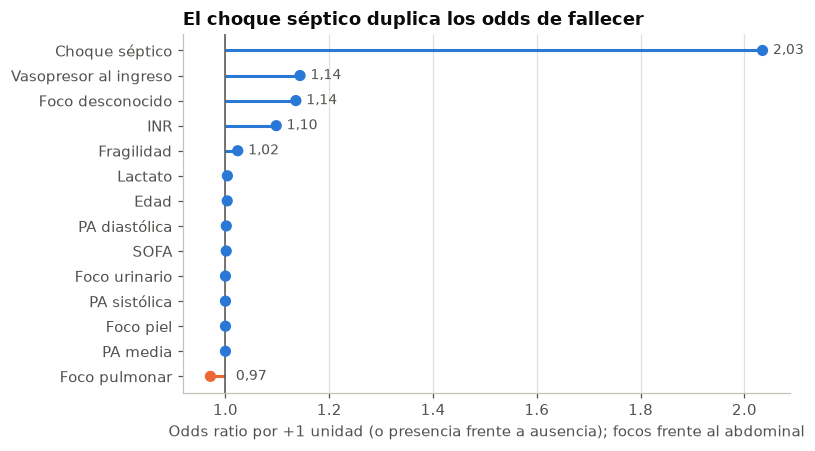

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
orden = coef["OR_por_unidad"].rename(index=ES).sort_values()
ax.hlines(orden.index, 1, orden.values, color=[AZUL if v >= 1 else NARANJA for v in orden.values], lw=2)
ax.scatter(orden.values, orden.index, color=[AZUL if v >= 1 else NARANJA for v in orden.values], s=40, zorder=3)
for nombre_v, v in orden.items():
    if abs(v - 1) > 0.02:
        ax.text(max(v, 1) + 0.02, nombre_v, c(v, 2), va="center", fontsize=9, color=TINTA2)  
ax.axvline(1, color=TINTA2, lw=1)
ax.set_xlabel("Odds ratio por +1 unidad (o presencia frente a ausencia); focos frente al abdominal")
ax.set_title("El choque séptico duplica los odds de fallecer"); ax.grid(axis="y", visible=False)
guardar("02_odds_ratios")

### 5.1 Calibración

El parámetro class_weight="balanced" asigna el mismo peso a fallecidos y sobrevivientes, lo que mejora la
detección de los pacientes que fallecen pero eleva las probabilidades por encima de la mortalidad real de la
cohorte (46,5 %). Como la aplicación muestra al médico un porcentaje de riesgo, este se corrige mediante la
calibración de Platt, que ajusta una segunda regresión logística sobre el puntaje del modelo para reescalarlo
de modo que coincida con la mortalidad observada. Esta regresión se entrena con predicciones de validación
cruzada, en las que cada paciente fue evaluado por un modelo que no lo había visto, para evitar una calibración
optimista. Al tratarse de una transformación monótona, no altera el orden de los pacientes ni el AUC; solo
ajusta la escala de las probabilidades.

In [10]:
sigmoide = lambda z: 1.0 / (1.0 + np.exp(-z))

z_cv = cross_val_predict(modelo, X_train, y_train, cv=cv5, method="decision_function") # log-odds fuera de fold
platt = LogisticRegression(C=1e6, max_iter=1000).fit(z_cv.reshape(-1, 1), y_train) # C enorme = sin regularizar
CAL_A, CAL_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])
print(f"Calibración de Platt: a = {CAL_A:.4f}, b = {CAL_B:.4f}  (logit de la prevalencia = {np.log(y_train.mean()/(1-y_train.mean())):.4f})")

def riesgo(Xd):
    """Probabilidad calibrada de fallecer en UCI para un DataFrame con las 11 variables.
    (Aquí se admiten NaN porque se evalúa el conjunto de prueba, que trae faltantes; la app no los admite.)"""
    return sigmoide(CAL_A * modelo.decision_function(Xd) + CAL_B)

p_cv = sigmoide(CAL_A * z_cv + CAL_B)# probabilidades calibradas fuera de fold (train)
p_test = riesgo(X_test)  # probabilidades calibradas (test)
p_test_sin_calibrar = modelo.predict_proba(X_test)[:, 1]
print(f"Riesgo medio predicho en test sin calibrar: {p_test_sin_calibrar.mean():.3f}")
print(f"Riesgo medio predicho en test calibrado: {p_test.mean():.3f}")
print(f"Mortalidad real en test: {y_test.mean():.3f}")
print(f"Rango de riesgos calibrados en test: entre {p_test.min():.3f} y {p_test.max():.3f}")

Calibración de Platt: a = 0.9858, b = -0.1467  (logit de la prevalencia = -0.1400)
Riesgo medio predicho en test sin calibrar: 0.501
Riesgo medio predicho en test calibrado: 0.465
Mortalidad real en test: 0.465
Rango de riesgos calibrados en test: entre 0.353 y 0.683


## 6. Umbrales y estratos de riesgo

Con un AUC cercano a 0,60, el modelo no tiene la precisión suficiente para emitir una predicción categórica
de si el paciente fallecerá o sobrevivirá. Por esta razón, la aplicación presenta la probabilidad calibrada y
la clasifica en uno de tres estratos de riesgo: menor, intermedio y mayor. Los dos puntos de corte que separan
estos estratos se definen con criterios explícitos a partir de las predicciones de validación cruzada, sin
utilizar el conjunto de prueba.

* **Corte inferior (umbral de alerta):** corresponde al valor a partir del cual el modelo identifica al 60 %
  de los pacientes que fallecen, es decir, una sensibilidad de 0,60. Es el mismo punto de operación elegido en
  la entrega 2, donde se priorizó reducir los falsos negativos, ya que no detectar a un paciente en riesgo
  tiene un costo clínico mayor que generar una alerta innecesaria.
* **Corte superior:** corresponde al valor que garantiza una especificidad de 0,85, lo que significa que el
  85% de los pacientes que sobreviven quedan por debajo de él. En consecuencia, los pacientes que lo superan
  conforman el grupo de mayor riesgo con un número reducido de falsas alarmas.

In [11]:
CORTE_BAJO = float(np.quantile(p_cv[y_train.values == 1], 0.40))# 60 % de los fallecidos queda por encima
CORTE_ALTO = float(np.quantile(p_cv[y_train.values == 0], 0.85)) # 85 % de los sobrevivientes queda por debajo
ESTRATOS = ["Menor riesgo", "Riesgo intermedio", "Mayor riesgo"]



def estratificar(p):
    return pd.Categorical(np.where(p >= CORTE_ALTO, ESTRATOS[2], np.where(p >= CORTE_BAJO, ESTRATOS[1], ESTRATOS[0])),
                          categories=ESTRATOS, ordered=True)

def tabla_estratos(p, y_real):
    t = pd.DataFrame({"estrato": estratificar(p), "p": p, "y": np.asarray(y_real)})
    g = t.groupby("estrato", observed=False).agg(n=("y", "size"), fallecidos=("y", "sum"),
                                                  mortalidad_observada=("y", "mean"), riesgo_medio_predicho=("p", "mean"))
    g["% de pacientes"] = g["n"] / g["n"].sum() * 100
    return g

print(f"Corte inferior (alerta): {CORTE_BAJO:.3f} | Corte superior: {CORTE_ALTO:.3f}\n")
estratos_cv, estratos_test = tabla_estratos(p_cv, y_train), tabla_estratos(p_test, y_test)
print("Validación cruzada (train):"); print(estratos_cv.round(3).to_string())
print("\nPrueba:"); print(estratos_test.round(3).to_string())

Corte inferior (alerta): 0.428 | Corte superior: 0.517

Validación cruzada (train):
                      n  fallecidos  mortalidad_observada  riesgo_medio_predicho  % de pacientes
estrato                                                                                         
Menor riesgo       3161        1302                 0.412                  0.407          45.177
Riesgo intermedio  2355        1033                 0.439                  0.449          33.657
Mayor riesgo       1481         919                 0.621                  0.614          21.166

Prueba:
                      n  fallecidos  mortalidad_observada  riesgo_medio_predicho  % de pacientes
estrato                                                                                         
Menor riesgo       1058         427                 0.404                  0.406          45.349
Riesgo intermedio   770         337                 0.438                  0.449          33.005
Mayor riesgo        505         32

## 7. Resultados en el conjunto de prueba

El conjunto de prueba (2.333 pacientes) se usa una sola vez.

In [12]:
def ic_bootstrap(funcion, *arreglos, n=2000, semilla=SEMILLA):
    """IC 95 % por bootstrap: se remuestrean pacientes con reemplazo y se recalcula la métrica."""
    rng = np.random.default_rng(semilla)
    arreglos = [np.asarray(a) for a in arreglos]
    valores = []
    for _ in range(n):
        idx = rng.integers(0, len(arreglos[0]), len(arreglos[0]))
        if len(np.unique(arreglos[0][idx])) < 2:
            continue
        valores.append(funcion(*[a[idx] for a in arreglos]))
    return [float(v) for v in np.percentile(valores, [2.5, 97.5])]

yt = y_test.values
auc = roc_auc_score(yt, p_test);              auc_ic = ic_bootstrap(roc_auc_score, yt, p_test)
auprc = average_precision_score(yt, p_test);  auprc_ic = ic_bootstrap(average_precision_score, yt, p_test)
brier = brier_score_loss(yt, p_test);         brier_ref = float(np.mean((yt - y_train.mean()) ** 2))
brier_sin_cal = brier_score_loss(yt, p_test_sin_calibrar)

# Pendiente e intercepto de calibración en test: lo ideal es pendiente 1 e intercepto 0.
logit_p = np.log(p_test / (1 - p_test))
recal = LogisticRegression(C=1e6, max_iter=1000).fit(logit_p.reshape(-1, 1), yt)
cal_pendiente, cal_intercepto = float(recal.coef_[0, 0]), float(recal.intercept_[0])

print(f"AUC-ROC  {auc:.3f}  IC95% [{auc_ic[0]:.3f}, {auc_ic[1]:.3f}]   (validación cruzada: {comparacion.iloc[0]['AUC CV']:.3f})")
print(f"AUPRC    {auprc:.3f}  IC95% [{auprc_ic[0]:.3f}, {auprc_ic[1]:.3f}]   (azar = prevalencia = {yt.mean():.3f})")
print(f"Brier    {brier:.4f}  (sin calibrar {brier_sin_cal:.4f}; predecir siempre la prevalencia {brier_ref:.4f})")
print(f"Calibración en test: pendiente {cal_pendiente:.3f}, intercepto {cal_intercepto:.3f}")

AUC-ROC  0.594  IC95% [0.571, 0.617]   (validación cruzada: 0.582)
AUPRC    0.566  IC95% [0.535, 0.598]   (azar = prevalencia = 0.465)
Brier    0.2400  (sin calibrar 0.2413; predecir siempre la prevalencia 0.2488)
Calibración en test: pendiente 1.144, intercepto 0.019


### 7.1 Comparación contra SOFA en la misma cohorte

SOFA al ingreso es el estándar que la médica asesora confirmó que se usa hoy. Se compara en los
pacientes de prueba que tienen SOFA registrado, y la diferencia de AUC se evalúa con bootstrap pareado.

n con SOFA: 2186 | AUC SOFA 0.564 [0.539, 0.587] | AUC modelo 0.595 | diferencia +0.031 IC95% [+0.007, +0.055]


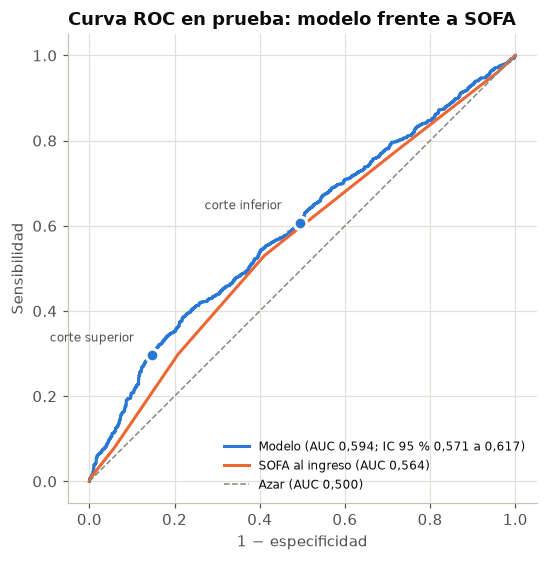

In [13]:
con_sofa = X_test["SOFA_0h"].notna().values
sofa = X_test.loc[con_sofa, "SOFA_0h"].values
auc_sofa = roc_auc_score(yt[con_sofa], sofa);            auc_sofa_ic = ic_bootstrap(roc_auc_score, yt[con_sofa], sofa)
auc_modelo_sub = roc_auc_score(yt[con_sofa], p_test[con_sofa])
dif = auc_modelo_sub - auc_sofa
dif_ic = ic_bootstrap(lambda a, b, c: roc_auc_score(a, b) - roc_auc_score(a, c), yt[con_sofa], p_test[con_sofa], sofa)
print(f"n con SOFA: {con_sofa.sum()} | AUC SOFA {auc_sofa:.3f} [{auc_sofa_ic[0]:.3f}, {auc_sofa_ic[1]:.3f}] | "
      f"AUC modelo {auc_modelo_sub:.3f} | diferencia {dif:+.3f} IC95% [{dif_ic[0]:+.3f}, {dif_ic[1]:+.3f}]")

fig, ax = plt.subplots(figsize=(5.6, 5.2))
fpr, tpr, _ = roc_curve(yt, p_test); fpr_s, tpr_s, _ = roc_curve(yt[con_sofa], sofa)
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"Modelo (AUC {c(auc)}; IC 95 % {c(auc_ic[0])} a {c(auc_ic[1])})")
ax.plot(fpr_s, tpr_s, color=NARANJA, lw=2, label=f"SOFA al ingreso (AUC {c(auc_sofa)})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--", label="Azar (AUC 0,500)")
for corte, etiqueta in [(CORTE_BAJO, "corte inferior"), (CORTE_ALTO, "corte superior")]:
    pred = p_test >= corte
    ax.scatter(pred[yt == 0].mean(), pred[yt == 1].mean(), s=70, color=AZUL, edgecolor="#ffffff", lw=2, zorder=5)
    ax.annotate(etiqueta, (pred[yt == 0].mean(), pred[yt == 1].mean()), textcoords="offset points", xytext=(-12, 9), ha="right", fontsize=8, color=TINTA2)
ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad"); ax.set_aspect("equal")
ax.set_title("Curva ROC en prueba: modelo frente a SOFA"); ax.legend(loc="lower right", fontsize=8)
guardar("03_roc_modelo_vs_sofa")

En los 2.186 pacientes de prueba con SOFA registrado, el modelo obtiene un AUC de 0,595, frente a 0,564 del SOFA al ingreso, escala utilizada actualmente por el intensivista. La diferencia es de 0,031, con un intervalo de confianza del 95 % entre 0,007 y 0,055. Dado que este intervalo no incluye el cero, la mejora es estadísticamente significativa, aunque de magnitud modesta. La curva del modelo se mantiene por encima de la del SOFA en prácticamente todo el rango, con una ventaja más evidente en la zona de alta especificidad, situada a la izquierda del gráfico, donde se encuentra el corte superior que define el estrato de mayor riesgo. Sin embargo, ambas curvas permanecen relativamente cerca de la diagonal del azar, lo que indica que tanto el modelo como SOFA presentan una capacidad de discriminación limitada en este conjunto de datos.

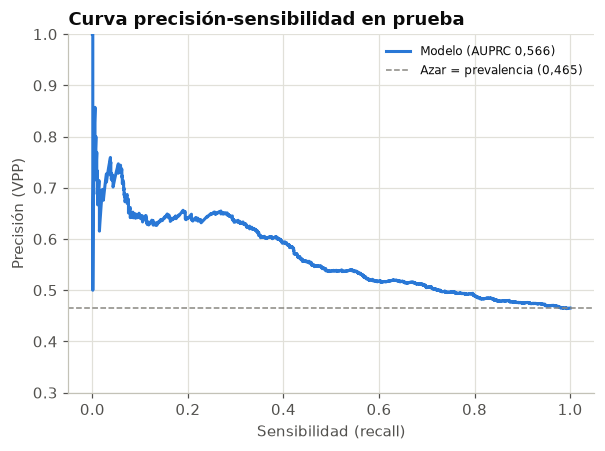

In [14]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
prec, rec, _ = precision_recall_curve(yt, p_test)
ax.plot(rec, prec, color=AZUL, lw=2, label=f"Modelo (AUPRC {c(auprc)})")
ax.axhline(yt.mean(), color=GRIS, lw=1, ls="--", label=f"Azar = prevalencia ({c(yt.mean())})")
ax.set_xlabel("Sensibilidad (recall)"); ax.set_ylabel("Precisión (VPP)"); ax.set_ylim(0.3, 1.0)
ax.set_title("Curva precisión-sensibilidad en prueba"); ax.legend(fontsize=8)
guardar("04_precision_recall")

La curva de precisión-sensibilidad muestra, para cada umbral, qué proporción de los pacientes clasificados como de alto riesgo fallece realmente (precisión o valor predictivo positivo) frente a la proporción de fallecidos que el modelo logra identificar (sensibilidad). El modelo obtiene un AUPRC de 0,566, superior al 0,465 que correspondería al azar, equivalente a la mortalidad observada en el conjunto de prueba. La curva se mantiene por encima de esta referencia en prácticamente todo el rango, aunque la diferencia es moderada. Cerca de una sensibilidad del 30%, correspondiente al corte superior, la precisión ronda el 64%: de cada diez pacientes identificados en el estrato de mayor riesgo, aproximadamente seis fallecen. A medida que se busca identificar a más fallecidos, la precisión tiende a disminuir hasta aproximarse a la prevalencia de mortalidad. Las oscilaciones del extremo izquierdo deben interpretarse con cautela, ya que en esa zona la precisión se calcula sobre un número reducido de pacientes.

### 7.2 Evaluación de la calibración en el conjunto de prueba

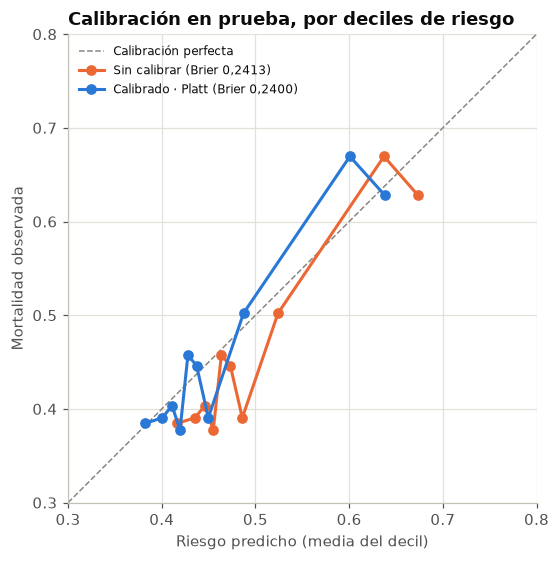

In [15]:
def curva_calibracion(p, y_real, n_grupos=10):
    t = pd.DataFrame({"p": p, "y": y_real})
    t["grupo"] = pd.qcut(t["p"].rank(method="first"), n_grupos, labels=False)
    return t.groupby("grupo").agg(predicho=("p", "mean"), observado=("y", "mean"), n=("y", "size"))

cal_antes, cal_despues = curva_calibracion(p_test_sin_calibrar, yt), curva_calibracion(p_test, yt)
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0.3, 0.8], [0.3, 0.8], color=GRIS, lw=1, ls="--", label="Calibración perfecta")
ax.plot(cal_antes["predicho"], cal_antes["observado"], "o-", color=NARANJA, lw=2, ms=6, label=f"Sin calibrar (Brier {c(brier_sin_cal, 4)})")
ax.plot(cal_despues["predicho"], cal_despues["observado"], "o-", color=AZUL, lw=2, ms=6, label=f"Calibrado · Platt (Brier {c(brier, 4)})")
ax.set_xlim(0.3, 0.8); ax.set_ylim(0.3, 0.8); ax.set_aspect("equal")
ax.set_xlabel("Riesgo predicho (media del decil)"); ax.set_ylabel("Mortalidad observada")
ax.set_title("Calibración en prueba, por deciles de riesgo"); ax.legend(loc="upper left", fontsize=8)
guardar("05_calibracion")

Los pacientes de prueba se dividieron en diez grupos (deciles) según su riesgo predicho, y en cada grupo se comparó el riesgo medio estimado con la mortalidad observada; en un modelo perfectamente calibrado, todos los puntos se ubicarían sobre la diagonal. Antes de la calibración (curva naranja), la mayoría de los puntos quedan por debajo de ella, lo que indica que el modelo sobrestimaba el riesgo como consecuencia del balanceo de clases. Tras aplicar la calibración de Platt (curva azul), los puntos se aproximan a la diagonal y el puntaje de Brier disminuye de 0,2413 a 0,2400, una mejora leve pero consistente. Las desviaciones que persisten en algunos deciles deben interpretarse con cautela, dado que cada grupo incluye alrededor de 230 pacientes. Por último, los riesgos calibrados se concentran entre el 38% y el 64% aproximadamente, por lo que la calibración solo puede valorarse dentro de ese intervalo y no en valores extremos.

### 7.3 Estratos de riesgo y distribución de las predicciones

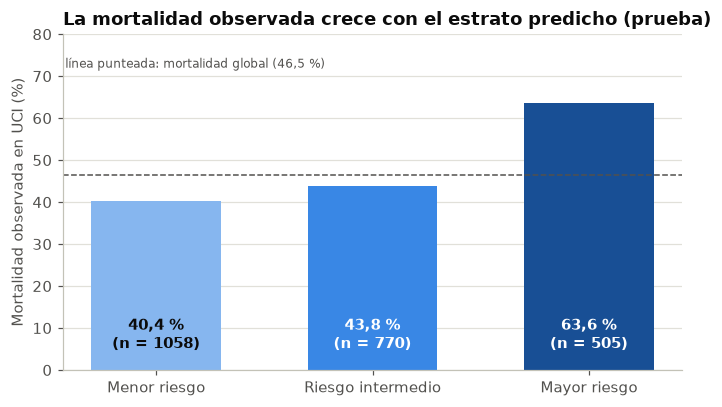

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
tonos = ["#86b6ef", "#3987e5", "#184f95"] 
barras = ax.bar(ESTRATOS, estratos_test["mortalidad_observada"] * 100, color=tonos, width=0.6)
for b, (_, fila) in zip(barras, estratos_test.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, 4, f"{c(fila['mortalidad_observada']*100, 1)} %\n(n = {int(fila['n'])})",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color=TINTA if b is barras[0] else "white")
ax.axhline(yt.mean() * 100, color=TINTA2, lw=1, ls="--"); ax.text(-0.42, 72, f"línea punteada: mortalidad global ({c(yt.mean() * 100, 1)} %)", ha="left", fontsize=8, color=TINTA2)
ax.set_ylim(0, 80); ax.set_ylabel("Mortalidad observada en UCI (%)")
ax.set_title("La mortalidad observada crece con el estrato predicho (prueba)"); ax.grid(axis="x", visible=False)
guardar("06_estratos_riesgo")

La mortalidad observada aumenta de forma ordenada a medida que sube el estrato predicho: 40,4% en el estrato de menor riesgo, 43,8% en el intermedio y 63,6% en el de mayor riesgo, frente a una mortalidad global del 46,5%. El hallazgo más relevante se encuentra en el estrato de mayor riesgo, que agrupa al 22% de los pacientes de prueba (505 de 2.333) y cuya mortalidad supera en 17,1 puntos porcentuales a la global. En cambio, la diferencia entre los estratos menor e intermedio es pequeña, de 3,4 puntos porcentuales, lo que indica que el modelo logra diferenciar con mayor claridad a los pacientes de mayor riesgo que a los de riesgo bajo e intermedio. Cabe destacar que incluso el estrato de menor riesgo presenta una mortalidad cercana al 40%, de modo que pertenecer a él no indica un riesgo bajo en términos absolutos, sino un riesgo menor en comparación con el resto de la cohorte.

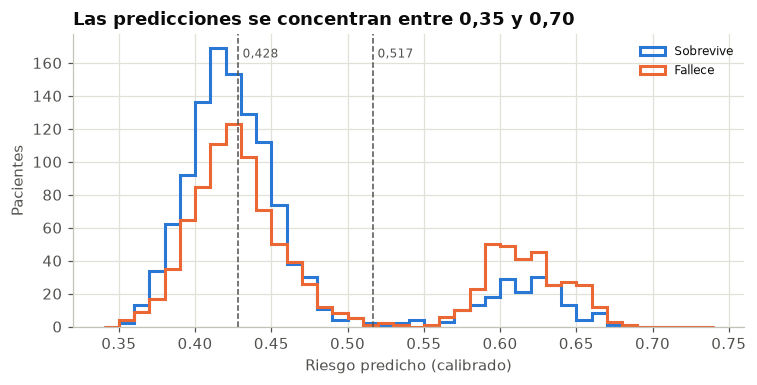

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0.34, 0.74, 41)
ax.hist(p_test[yt == 0], bins=bins, color=AZUL, histtype="step", lw=2, label="Sobrevive")
ax.hist(p_test[yt == 1], bins=bins, color=NARANJA, histtype="step", lw=2, label="Fallece")
for corte in (CORTE_BAJO, CORTE_ALTO):
    ax.axvline(corte, color=TINTA2, lw=1, ls="--")
    ax.text(corte + 0.003, ax.get_ylim()[1] * 0.92, c(corte), fontsize=8, color=TINTA2)
ax.set_xlabel("Riesgo predicho (calibrado)"); ax.set_ylabel("Pacientes")
ax.set_title("Las predicciones se concentran entre 0,35 y 0,70"); ax.legend(fontsize=8)
guardar("07_distribucion_riesgos")

La distribución de los riesgos predichos es bimodal: la mayoría de los pacientes se concentra entre 0,35 y 0,50, y un grupo más pequeño entre 0,55 y 0,70, con muy pocos pacientes en el intervalo intermedio. Esta separación se explica por el choque séptico, la variable de mayor peso en el modelo (odds ratio de 2,03): en el conjunto de prueba, todos los pacientes con choque séptico se ubican en la agrupación de riesgo alto y ninguno sin choque séptico alcanza el estrato de mayor riesgo. En el grupo de riesgo alto predominan los pacientes que fallecen, mientras que en el grupo de riesgo bajo las distribuciones de fallecidos y supervivientes se superponen ampliamente, lo que evidencia una capacidad limitada para distinguir ambos desenlaces en ese intervalo. El corte superior (0,517) se ubica en el espacio entre ambas agrupaciones, por lo que el estrato de mayor riesgo corresponde, en gran medida, al grupo de predicciones más altas. El corte inferior (0,428), en cambio, divide la agrupación de menor riesgo en una zona donde la superposición es considerable. Esto ayuda a explicar por qué la diferencia de mortalidad entre los estratos menor e intermedio es pequeña, mientras que el estrato de mayor riesgo presenta una mortalidad observada claramente superior.

### 7.4 Aciertos y errores del modelo en los puntos de corte

                               corte   VP   FP   FN    VN  sensibilidad  especificidad    VPP    VPN  accuracy     F1
Corte inferior (alerta)        0.428  658  617  427   631         0.606          0.506  0.516  0.596     0.553  0.558
Corte superior (mayor riesgo)  0.517  321  184  764  1064         0.296          0.853  0.636  0.582     0.594  0.404


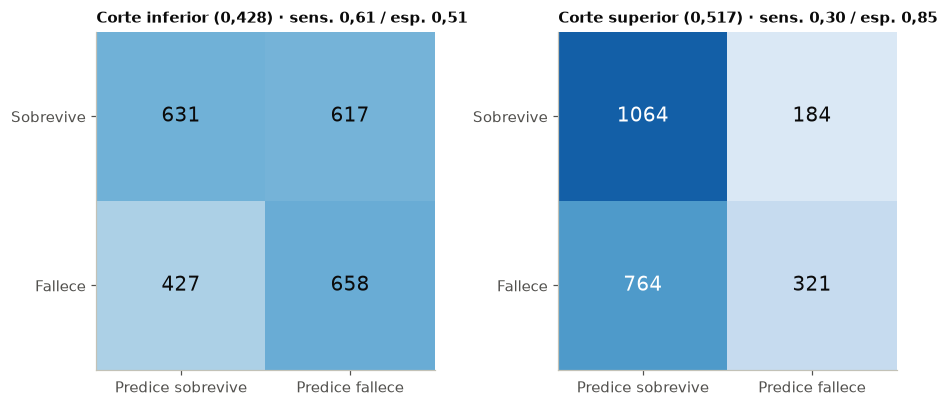

In [19]:
def metricas_en_corte(p, y_real, corte):
    vn, fp, fn, vp = confusion_matrix(y_real, (p >= corte).astype(int)).ravel()
    return {"corte": corte, "VP": int(vp), "FP": int(fp), "FN": int(fn), "VN": int(vn),
            "sensibilidad": vp / (vp + fn), "especificidad": vn / (vn + fp),
            "VPP": vp / (vp + fp), "VPN": vn / (vn + fn), "accuracy": (vp + vn) / len(y_real),
            "F1": 2 * vp / (2 * vp + fp + fn)}

m_bajo, m_alto = metricas_en_corte(p_test, yt, CORTE_BAJO), metricas_en_corte(p_test, yt, CORTE_ALTO)
tabla_cortes = pd.DataFrame([m_bajo, m_alto], index=["Corte inferior (alerta)", "Corte superior (mayor riesgo)"])
display(tabla_cortes.round(3)) if "display" in dir() else print(tabla_cortes.round(3).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(8.6, 3.8))
for ax, m, titulo in zip(ejes, [m_bajo, m_alto], ["Corte inferior", "Corte superior"]):
    mat = np.array([[m["VN"], m["FP"]], [m["FN"], m["VP"]]])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=1300)
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, f"{v}", ha="center", va="center", fontsize=13, color="white" if v > 700 else TINTA)
    ax.set_xticks([0, 1], ["Predice sobrevive", "Predice fallece"]); ax.set_yticks([0, 1], ["Sobrevive", "Fallece"])
    ax.set_title(f"{titulo} ({c(m['corte'])}) · sens. {c(m['sensibilidad'], 2)} / esp. {c(m['especificidad'], 2)}", fontsize=10); ax.grid(False)
guardar("08_matrices_confusion")

Cada matriz muestra cómo se clasifican los 2.333 pacientes de prueba cuando se considera como "predice fallece" a todo paciente cuyo riesgo supera el corte correspondiente.

Con el corte inferior (42,8%), el modelo identifica a 658 de los 1.085 pacientes que fallecen (sensibilidad de 0,61), pero también señala a 617 de los 1.248 que sobreviven (especificidad de 0,51). Solo el 52% de los pacientes señalados fallece realmente (valor predictivo positivo), por lo que este corte funciona como una alerta amplia: prioriza una mayor sensibilidad a costa de numerosas falsas alarmas, aunque todavía deja sin identificar al 39% de los fallecidos.

Con el corte superior (51,7%), el modelo señala a muchos menos pacientes, 505 en total, de los cuales fallece el 64% (valor predictivo positivo de 0,64). Las falsas alarmas disminuyen a 184 y la especificidad aumenta a 0,85. Sin embargo, la sensibilidad cae a 0,30, por lo que 764 pacientes que fallecen quedan clasificados por debajo del corte.

Ninguno de los dos cortes ofrece simultáneamente una sensibilidad y una especificidad elevadas, lo que es coherente con la capacidad discriminativa limitada del modelo. Por esta razón, la aplicación no utiliza estos cortes como reglas de decisión clínica, sino para ubicar al paciente en un estrato de riesgo y mostrar la mortalidad observada en él. La exactitud (accuracy) y el F1 se reportan como referencia, pero son menos informativos para esta finalidad porque no consideran los diferentes costos clínicos de los falsos negativos y las falsas alarmas.

### 7.5 Beneficio clínico del uso del modelo

El análisis de curva de decisión evalúa si utilizar el modelo para decidir a qué pacientes intensificar la vigilancia aporta más beneficio que las dos alternativas sin modelo: vigilar a todos los pacientes o no vigilar a ninguno. Para ello se calcula el beneficio neto en distintos umbrales de decisión. Cada umbral representa el riesgo mínimo a partir del cual el médico consideraría justificado intervenir y refleja cuánto pesa una falsa alarma frente a un caso no detectado: un umbral bajo indica que se prefiere vigilar de más antes que pasar por alto a un paciente, y uno alto indica lo contrario. El beneficio neto suma la proporción de pacientes que fallecen y son identificados correctamente (verdaderos positivos) y resta la proporción de falsas alarmas (falsos positivos), ponderada según el umbral elegido. Un modelo es útil en los umbrales en los que su beneficio neto supera al de ambas alternativas.

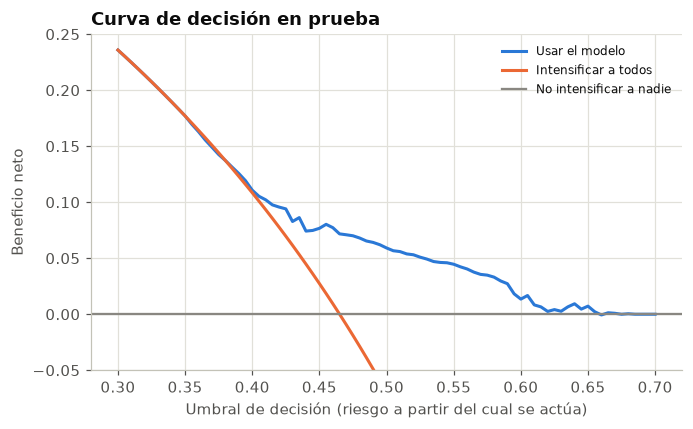

El modelo supera a ambas estrategias simples entre umbrales 0.39 y 0.65 (mejora máxima de beneficio neto: 0.072 en pt = 0.46)


In [20]:
umbrales = np.linspace(0.30, 0.70, 81)
def beneficio_neto(p, y_real, pt):
    pred = p >= pt
    return (pred & (y_real == 1)).sum() / len(y_real) - (pred & (y_real == 0)).sum() / len(y_real) * pt / (1 - pt)

bn_modelo = np.array([beneficio_neto(p_test, yt, t) for t in umbrales])
bn_todos = np.array([yt.mean() - (1 - yt.mean()) * t / (1 - t) for t in umbrales])
mejora = bn_modelo - np.maximum(bn_todos, 0)
rango_util = umbrales[mejora > 0.002]
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(umbrales, bn_modelo, color=AZUL, lw=2, label="Usar el modelo")
ax.plot(umbrales, bn_todos, color=NARANJA, lw=2, label="Intensificar a todos")
ax.axhline(0, color=GRIS, lw=1.5, label="No intensificar a nadie")
ax.set_ylim(-0.05, 0.25); ax.set_xlabel("Umbral de decisión (riesgo a partir del cual se actúa)"); ax.set_ylabel("Beneficio neto")
ax.set_title("Curva de decisión en prueba"); ax.legend(fontsize=8)
guardar("09_curva_decision")
print(f"El modelo supera a ambas estrategias simples entre umbrales {rango_util.min():.2f} y {rango_util.max():.2f} "
      f"(mejora máxima de beneficio neto: {mejora.max():.3f} en pt = {umbrales[mejora.argmax()]:.2f})")

La curva compara el beneficio neto de tres estrategias según el umbral de riesgo a partir del cual el médico decidiría intensificar la vigilancia. Para umbrales inferiores a 0,39, utilizar el modelo ofrece un beneficio prácticamente equivalente al de intensificar la vigilancia en todos los pacientes, ya que con niveles de riesgo tan bajos ambas estrategias producen resultados similares. Entre aproximadamente 0,39 y 0,65, el modelo presenta un beneficio neto superior al de las dos alternativas. Aunque su beneficio neto tiende a disminuir a medida que aumenta el umbral, mantiene una ventaja frente a intensificar la vigilancia en todos los pacientes, especialmente cuando esta última estrategia comienza a perder utilidad. A partir de 0,465, valor que coincide con la mortalidad observada, intensificar la vigilancia en todos los pacientes deja de ofrecer un beneficio neto positivo. Por encima de 0,65, el beneficio del modelo se aproxima a cero, debido a que muy pocos pacientes alcanzan esos niveles de riesgo, por lo que su resultado se asemeja al de no intensificar la vigilancia en ninguno. En consecuencia, el modelo muestra una posible utilidad clínica dentro de un rango limitado de umbrales, que incluye los dos puntos de corte utilizados para definir los estratos (0,428 y 0,517). Sin embargo, este beneficio potencial debe interpretarse con cautela, ya que su aplicación clínica dependerá de los costos y beneficios reales de las intervenciones asociadas a cada nivel de riesgo.

## 8. Explicación por paciente

En un modelo lineal, la contribución de cada variable se calcula de forma exacta: es su coeficiente multiplicado por la diferencia entre el valor del paciente y el promedio de entrenamiento. Un valor positivo eleva el riesgo y uno negativo lo reduce. Este cálculo coincide con los valores SHAP de la entrega 2 y es el que muestra la aplicación.

InfectionSource    desconocido
SepticShock                1.0
VasopressorUse_0h          1.0
MAP_0                     58.0
SOFA_0h                    3.0
DBP_0                     64.0
SBP_0                     64.0
Lactate_0h                 5.0
INR_0h                    1.47
Age                       88.0
FrailtyScore               7.0

Riesgo calibrado: 0.683


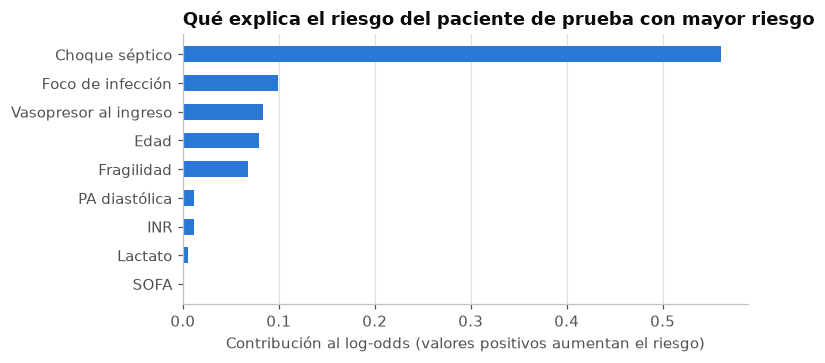

In [22]:
X_train_t = pd.DataFrame(pre.transform(X_train), columns=NOMBRES, index=X_train.index)
FONDO = X_train_t.mean()                                   # paciente "promedio" de entrenamiento
VALOR_BASE = float(logit.intercept_[0] + (logit.coef_[0] * FONDO.values).sum())

def explicar(fila):
    """Contribuciones (en log-odds) de cada variable para un paciente (DataFrame de una fila)."""
    xt = pd.Series(pre.transform(fila)[0], index=NOMBRES)
    contrib = pd.Series(logit.coef_[0], index=NOMBRES) * (xt - FONDO)
    assert np.isclose(VALOR_BASE + contrib.sum(), modelo.decision_function(fila)[0])      # la explicación cuadra
    return contrib

ejemplo = X_test.iloc[[int(np.argmax(p_test))]]            # paciente de prueba con mayor riesgo predicho
contrib = explicar(ejemplo)
focos = [n for n in NOMBRES if n.startswith("InfectionSource_")]          # las dummies del foco se suman en una sola barra
contrib = pd.concat([contrib.drop(focos), pd.Series({"Foco de infección": contrib[focos].sum()})]).rename(index=ES).sort_values(key=np.abs)
contrib = contrib[contrib.abs() > 1e-4]
print(ejemplo.T.to_string(header=False)); print(f"\nRiesgo calibrado: {riesgo(ejemplo)[0]:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(contrib.index, contrib.values, color=[AZUL if v > 0 else NARANJA for v in contrib.values], height=0.55)
ax.set_xlabel("Contribución al log-odds (valores positivos aumentan el riesgo)")
ax.set_title("Qué explica el riesgo del paciente de prueba con mayor riesgo"); ax.grid(axis="y", visible=False)
guardar("10_explicacion_paciente")

En el paciente de prueba con mayor riesgo predicho (68,3%), el choque séptico es, con amplia diferencia, el factor que más contribuye a elevar el riesgo, seguido del foco de infección desconocido, el uso de vasopresores al ingreso, la edad avanzada (88 años) y la fragilidad. Las demás variables presentan contribuciones mucho menores, mientras que el SOFA tiene una influencia prácticamente nula en esta predicción, esto se debe a que su coeficiente en el modelo es muy cercano a cero.

## 9. Exportación del artefacto

El modelo se serializa en un único artefacto que contiene todos los componentes requeridos por la aplicación: el Pipeline ajustado, los parámetros de calibración, los puntos de corte de los estratos, los rangos admisibles de cada variable, empleados para validar los datos ingresados y las métricas de desempeño. De este modo, la aplicación no realiza ningún reentrenamiento ni recálculo; se limita a cargar el artefacto y generar las predicciones, lo que garantiza que el modelo desplegado sea idéntico al evaluado en este cuaderno.

In [23]:
rangos = {c: {"min": float(X_train[c].min()), "p01": float(X_train[c].quantile(0.01)), "mediana": float(X_train[c].median()),
              "p99": float(X_train[c].quantile(0.99)), "max": float(X_train[c].max()),
              "pct_faltante": float(X_train[c].isna().mean() * 100)} for c in COLS_NUM}
categorias = sorted(X_train["InfectionSource"].dropna().unique().tolist())

def a_dict(tabla):
    """Tabla → diccionario serializable (los NaN pasan a None para que el JSON sea válido)."""
    return {str(k): {c: (None if pd.isna(v) else float(v)) for c, v in fila.items()} for k, fila in tabla.iterrows()}

metricas = {
    "fecha_entrenamiento": datetime.now(timezone.utc).strftime("%Y-%m-%d"),
    "n_total": int(len(df)), "n_utilizable": int(len(datos)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "mortalidad": float(y.mean()),
    "auc_cv": float(comparacion.iloc[0]["AUC CV"]), "auc_cv_de": float(comparacion.iloc[0]["± DE"]),
    "auc_test": float(auc), "auc_test_ic95": auc_ic, "auprc_test": float(auprc), "auprc_test_ic95": auprc_ic,
    "brier_test": float(brier), "brier_test_sin_calibrar": float(brier_sin_cal), "brier_referencia": brier_ref,
    "calibracion_pendiente": cal_pendiente, "calibracion_intercepto": cal_intercepto,
    "sofa": {"n": int(con_sofa.sum()), "auc": float(auc_sofa), "auc_ic95": auc_sofa_ic, "auc_modelo_misma_muestra": float(auc_modelo_sub),
             "diferencia": float(dif), "diferencia_ic95": dif_ic},
    "cortes": {"bajo": CORTE_BAJO, "alto": CORTE_ALTO},
    "en_corte_bajo": {k: float(v) for k, v in m_bajo.items()}, "en_corte_alto": {k: float(v) for k, v in m_alto.items()},
    "estratos_test": a_dict(estratos_test), "estratos_cv": a_dict(estratos_cv),
    "riesgo_min_test": float(p_test.min()), "riesgo_max_test": float(p_test.max()),
    "curva_decision": {"umbral_min_util": float(rango_util.min()), "umbral_max_util": float(rango_util.max()), "mejora_maxima": float(mejora.max())},
}
artefacto = {
    "pipeline": modelo, "calibracion": {"a": CAL_A, "b": CAL_B}, "cortes": {"bajo": CORTE_BAJO, "alto": CORTE_ALTO},
    "estratos": ESTRATOS, "cols_cat": COLS_CAT, "cols_num": COLS_NUM, "cols_bin": COLS_BIN, "variables": VARIABLES,
    "categorias_foco": categorias, "nombres_transformados": NOMBRES, "fondo": FONDO.to_dict(), "valor_base": VALOR_BASE,
    "coeficientes": a_dict(coef), "intercepto": float(logit.intercept_[0]),
    "rangos": rangos, "metricas": metricas,
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
joblib.dump(artefacto, DIR_MODELOS / "modelo_sepsis.joblib", compress=3)
(DIR_MODELOS / "metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print("Artefacto:", DIR_MODELOS / "modelo_sepsis.joblib", f"({(DIR_MODELOS / 'modelo_sepsis.joblib').stat().st_size / 1024:.0f} KB)")

Artefacto: c:\Users\sgr26\Desktop\U\Sexto Semestre\IA\Proyecto 3\sepsis_uci_mortalidad\sepsis_uci_mortalidad\models\modelo_sepsis.joblib (93 KB)


In [24]:
# Prueba de verificación del artefacto.
# Se carga el archivo guardado y se comprueba que reproduce las mismas predicciones obtenidas en el cuaderno.
recargado = joblib.load(DIR_MODELOS / "modelo_sepsis.joblib")
z = recargado["pipeline"].decision_function(X_test)
p_recargado = sigmoide(recargado["calibracion"]["a"] * z + recargado["calibracion"]["b"])
assert np.allclose(p_recargado, p_test)

# Paciente de ejemplo con todos los datos completos.
un_paciente = pd.DataFrame([{"InfectionSource": "pulmonar", "SepticShock": 1, "VasopressorUse_0h": 1, "MAP_0": 58, "SOFA_0h": 4,
                             "DBP_0": 45, "SBP_0": 84, "Lactate_0h": 4.8, "INR_0h": 1.6, "Age": 78, "FrailtyScore": 6}])[VARIABLES]

# Procedimiento usado en producción, se aplican el escalado, la codificación del foco de infección
# y la regresión logística, omitiendo el imputador. El resultado debe coincidir con el del Pipeline completo.
xt = np.concatenate([escalador.transform(un_paciente[COLS_NUM])[0],
                     pre.named_transformers_["cat"].named_steps["onehot"].transform(un_paciente[COLS_CAT].values)[0]])
z_sin_imputador = float(logit.decision_function(xt.reshape(1, -1))[0])
assert np.isclose(z_sin_imputador, modelo.decision_function(un_paciente)[0])

print("Las predicciones del artefacto guardado coinciden con las del cuaderno.")
print(f"Riesgo del paciente de ejemplo: {riesgo(un_paciente)[0]:.3f} (estrato: {estratificar(riesgo(un_paciente))[0]})")
print("El resultado es el mismo con y sin el imputador.")

Las predicciones del artefacto guardado coinciden con las del cuaderno.
Riesgo del paciente de ejemplo: 0.631 (estrato: Mayor riesgo)
El resultado es el mismo con y sin el imputador.


Como consideración de privacidad, el imputador, aunque no se usa en la aplicación, permanece dentro del Pipeline exportado y conserva los datos de entrenamiento. En un escenario real, el archivo del modelo debería protegerse como información de pacientes o exportarse sin ese componente.

## Conclusiones

* El modelo final es la regresión logística con regularización L1 seleccionada en la entrega 2, integrada en un único Pipeline ajustado con los datos de entrenamiento y con probabilidades calibradas mediante el método de Platt.
* Su capacidad de discriminación es modesta pero consistente: supera al azar y a la escala SOFA en la misma cohorte (AUC de 0,594 frente a 0,564), y su desempeño es similar en validación cruzada y en prueba, lo que indica ausencia de sobreajuste.
* Las probabilidades calibradas se ajustan razonablemente a la mortalidad observada, aunque se concentran en un rango estrecho, aproximadamente entre el 35% y el 70%. El modelo distingue principalmente a los pacientes con choque séptico del resto; por esta razón, la aplicación presenta el riesgo en tres estratos, con una mortalidad observada de 40,4%, 43,8% y 63,6%, junto con la explicación de cada predicción, en lugar de una clasificación binaria.
* Las limitaciones de desempeño parecen provenir del conjunto de datos, que muestra una señal débil incluso para la escala SOFA, lo que es coherente con la hipótesis de que los datos son sintéticos o fueron alterados durante su anonimización. El flujo de procesamiento y la aplicación permiten reentrenar el modelo con datos reales sin modificar el código.